In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n_array = []
    wtot_array = []
    for i in range(0, len(w_array)):
        n_array.append( df[df.w == w_array[i]].shape[0] )
        wtot_array.append( sum(df[df.w == w_array[i]]['w']) )
    n = 0
    for i in range(0, len(w_array)):
        if (wtot_array[i] != 0):
            n += wtot_array[i]*n_array[i]/sum(wtot_array)
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err

def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

Read root files into dataframes

In [3]:
observables1 = ['pt','b','w','reject','pt1','pt2','y1','y2','phi1','phi2','nef','evid']
observabless1 = ['pts','bs','ws','rejects','pt1s','pt2s','y1s','y2s','phi1s','phi2s','nefs','evids']

In [4]:
df_allreco = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0818_2.root', "MatchedTree"), 'pts>15 and bs!=-9 and reject<=0 and rejects<=0')

In [5]:
print(df_allreco.shape[0])

2528083


In [6]:
distance1 = []
distance2 = []
for i in range(0,df_allreco.shape[0]):
    if (i % 10000 == 0):
        print("processed", i, "rows")
    phi1small = min(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi1large = max(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi2small = min(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    phi2large = max(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_allreco.iloc[i]['y1']-df_allreco.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_allreco.iloc[i]['y2']-df_allreco.iloc[i]['y2s'])**2))
df_allreco['distance1'] = distance1
df_allreco['distance2'] = distance2

processed 0 rows
processed 10000 rows
processed 20000 rows
processed 30000 rows
processed 40000 rows
processed 50000 rows
processed 60000 rows
processed 70000 rows
processed 80000 rows
processed 90000 rows
processed 100000 rows
processed 110000 rows
processed 120000 rows
processed 130000 rows
processed 140000 rows
processed 150000 rows
processed 160000 rows
processed 170000 rows
processed 180000 rows
processed 190000 rows
processed 200000 rows
processed 210000 rows
processed 220000 rows
processed 230000 rows
processed 240000 rows
processed 250000 rows
processed 260000 rows
processed 270000 rows
processed 280000 rows
processed 290000 rows
processed 300000 rows
processed 310000 rows
processed 320000 rows
processed 330000 rows
processed 340000 rows
processed 350000 rows
processed 360000 rows
processed 370000 rows
processed 380000 rows
processed 390000 rows
processed 400000 rows
processed 410000 rows
processed 420000 rows
processed 430000 rows
processed 440000 rows
processed 450000 rows
pr

In [7]:
df_allreco.to_csv('/vast/palmer/home.grace/ys668/output/run12/all0818_2_allreco.csv', index=False)

In [9]:
df_alltruth = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0818_2.root', "MatchedTree"), 'pt>5 and b!=-9 and reject<=0 and rejects<=0')

In [10]:
df_alltruth.shape[0]

6558306

In [11]:
distance1 = []
distance2 = []
for i in range(0,df_alltruth.shape[0]):
    if (i % 10000 == 0):
        print("processed", i, "rows")
    phi1small = min(df_alltruth.iloc[i]['phi1'], df_alltruth.iloc[i]['phi1s'])
    phi1large = max(df_alltruth.iloc[i]['phi1'], df_alltruth.iloc[i]['phi1s'])
    phi2small = min(df_alltruth.iloc[i]['phi2'], df_alltruth.iloc[i]['phi2s'])
    phi2large = max(df_alltruth.iloc[i]['phi2'], df_alltruth.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_alltruth.iloc[i]['phi1'], df_alltruth.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_alltruth.iloc[i]['y1']-df_alltruth.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_alltruth.iloc[i]['y2']-df_alltruth.iloc[i]['y2s'])**2))
df_alltruth['distance1'] = distance1
df_alltruth['distance2'] = distance2

processed 0 rows
processed 10000 rows
processed 20000 rows
processed 30000 rows
processed 40000 rows
processed 50000 rows
processed 60000 rows
processed 70000 rows
processed 80000 rows
processed 90000 rows
processed 100000 rows
processed 110000 rows
processed 120000 rows
processed 130000 rows
processed 140000 rows
processed 150000 rows
processed 160000 rows
processed 170000 rows
processed 180000 rows
processed 190000 rows
processed 200000 rows
processed 210000 rows
processed 220000 rows
processed 230000 rows
processed 240000 rows
processed 250000 rows
processed 260000 rows
processed 270000 rows
processed 280000 rows
processed 290000 rows
processed 300000 rows
processed 310000 rows
processed 320000 rows
processed 330000 rows
processed 340000 rows
processed 350000 rows
processed 360000 rows
processed 370000 rows
processed 380000 rows
processed 390000 rows
processed 400000 rows
processed 410000 rows
processed 420000 rows
processed 430000 rows
processed 440000 rows
processed 450000 rows
pr

processed 3620000 rows
processed 3630000 rows
processed 3640000 rows
processed 3650000 rows
processed 3660000 rows
processed 3670000 rows
processed 3680000 rows
processed 3690000 rows
processed 3700000 rows
processed 3710000 rows
processed 3720000 rows
processed 3730000 rows
processed 3740000 rows
processed 3750000 rows
processed 3760000 rows
processed 3770000 rows
processed 3780000 rows
processed 3790000 rows
processed 3800000 rows
processed 3810000 rows
processed 3820000 rows
processed 3830000 rows
processed 3840000 rows
processed 3850000 rows
processed 3860000 rows
processed 3870000 rows
processed 3880000 rows
processed 3890000 rows
processed 3900000 rows
processed 3910000 rows
processed 3920000 rows
processed 3930000 rows
processed 3940000 rows
processed 3950000 rows
processed 3960000 rows
processed 3970000 rows
processed 3980000 rows
processed 3990000 rows
processed 4000000 rows
processed 4010000 rows
processed 4020000 rows
processed 4030000 rows
processed 4040000 rows
processed 4

In [12]:
df_alltruth.to_csv('/vast/palmer/home.grace/ys668/output/run12/all0818_2_alltruth.csv', index=False)

In [8]:
df_all = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0818_2.root', "MatchedTree"), 'reject<=0 and rejects<=0')

In [10]:
print(df_all.shape[0])

7649171


In [11]:
distance1 = []
distance2 = []
for i in range(0,df_all.shape[0]):
    if (i % 10000 == 0):
        print("processed", i, "rows")
    phi1small = min(df_all.iloc[i]['phi1'], df_all.iloc[i]['phi1s'])
    phi1large = max(df_all.iloc[i]['phi1'], df_all.iloc[i]['phi1s'])
    phi2small = min(df_all.iloc[i]['phi2'], df_all.iloc[i]['phi2s'])
    phi2large = max(df_all.iloc[i]['phi2'], df_all.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_all.iloc[i]['phi1'], df_all.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_all.iloc[i]['y1']-df_all.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_all.iloc[i]['y2']-df_all.iloc[i]['y2s'])**2))
df_all['distance1'] = distance1
df_all['distance2'] = distance2

processed 0 rows
processed 10000 rows
processed 20000 rows
processed 30000 rows
processed 40000 rows
processed 50000 rows
processed 60000 rows
processed 70000 rows
processed 80000 rows
processed 90000 rows
processed 100000 rows
processed 110000 rows
processed 120000 rows
processed 130000 rows
processed 140000 rows
processed 150000 rows
processed 160000 rows
processed 170000 rows
processed 180000 rows
processed 190000 rows
processed 200000 rows
processed 210000 rows
processed 220000 rows
processed 230000 rows
processed 240000 rows
processed 250000 rows
processed 260000 rows
processed 270000 rows
processed 280000 rows
processed 290000 rows
processed 300000 rows
processed 310000 rows
processed 320000 rows
processed 330000 rows
processed 340000 rows
processed 350000 rows
processed 360000 rows
processed 370000 rows
processed 380000 rows
processed 390000 rows
processed 400000 rows
processed 410000 rows
processed 420000 rows
processed 430000 rows
processed 440000 rows
processed 450000 rows
pr

processed 3620000 rows
processed 3630000 rows
processed 3640000 rows
processed 3650000 rows
processed 3660000 rows
processed 3670000 rows
processed 3680000 rows
processed 3690000 rows
processed 3700000 rows
processed 3710000 rows
processed 3720000 rows
processed 3730000 rows
processed 3740000 rows
processed 3750000 rows
processed 3760000 rows
processed 3770000 rows
processed 3780000 rows
processed 3790000 rows
processed 3800000 rows
processed 3810000 rows
processed 3820000 rows
processed 3830000 rows
processed 3840000 rows
processed 3850000 rows
processed 3860000 rows
processed 3870000 rows
processed 3880000 rows
processed 3890000 rows
processed 3900000 rows
processed 3910000 rows
processed 3920000 rows
processed 3930000 rows
processed 3940000 rows
processed 3950000 rows
processed 3960000 rows
processed 3970000 rows
processed 3980000 rows
processed 3990000 rows
processed 4000000 rows
processed 4010000 rows
processed 4020000 rows
processed 4030000 rows
processed 4040000 rows
processed 4

processed 7190000 rows
processed 7200000 rows
processed 7210000 rows
processed 7220000 rows
processed 7230000 rows
processed 7240000 rows
processed 7250000 rows
processed 7260000 rows
processed 7270000 rows
processed 7280000 rows
processed 7290000 rows
processed 7300000 rows
processed 7310000 rows
processed 7320000 rows
processed 7330000 rows
processed 7340000 rows
processed 7350000 rows
processed 7360000 rows
processed 7370000 rows
processed 7380000 rows
processed 7390000 rows
processed 7400000 rows
processed 7410000 rows
processed 7420000 rows
processed 7430000 rows
processed 7440000 rows
processed 7450000 rows
processed 7460000 rows
processed 7470000 rows
processed 7480000 rows
processed 7490000 rows
processed 7500000 rows
processed 7510000 rows
processed 7520000 rows
processed 7530000 rows
processed 7540000 rows
processed 7550000 rows
processed 7560000 rows
processed 7570000 rows
processed 7580000 rows
processed 7590000 rows
processed 7600000 rows
processed 7610000 rows
processed 7

In [12]:
df_allreco.to_csv('/vast/palmer/home.grace/ys668/output/run12/all0818_2_all.csv', index=False)

Read csv files into dataframes

In [55]:
df_allreco = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/all0818_2_allreco.csv')
df_alltruth = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/all0818_2_alltruth.csv')

In [56]:
df_allfake = applyCut(df_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')
df_match = applyCut(df_allreco, 'pt!=-9 and b!=-9 and distance1<0.02 and distance2<0.02')

In [57]:
df_fake1 = applyCut(df_allreco, 'pt==-9')
df_fake2 = applyCut(df_allreco, 'pt!=-9 and b==-9')
df_fake3 = applyCut(df_allreco, 'pt!=-9 and b!=-9 and (distance1>0.02 or distance2>0.02)')

In [58]:
df_match.shape[0]

1549662

1.1 Fake decomposition

In [59]:
w_array = np.unique(df_match['w'])

In [60]:
df_allreco_pts_array = [ df_allreco[(df_allreco.pts>15) & (df_allreco.pts<20)],\
                       df_allreco[(df_allreco.pts>20) & (df_allreco.pts<25) & (df_allreco.ws<1e-9)],\
                       df_allreco[(df_allreco.pts>25) & (df_allreco.pts<30)],\
                       df_allreco[(df_allreco.pts>30) & (df_allreco.pts<40)] ]

df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25) & (df_match.ws<1e-9)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)] ]

df_allfake_pts_array = [ df_allfake[(df_allfake.pts>15) & (df_allfake.pts<20)],\
                       df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25) & (df_allfake.ws<1e-9)],\
                       df_allfake[(df_allfake.pts>25) & (df_allfake.pts<30)],\
                       df_allfake[(df_allfake.pts>30) & (df_allfake.pts<40)] ]

In [61]:
df_fake1_pts_array = [ df_fake1[(df_fake1.pts>15) & (df_fake1.pts<20)],\
                       df_fake1[(df_fake1.pts>20) & (df_fake1.pts<25)],\
                       df_fake1[(df_fake1.pts>25) & (df_fake1.pts<30)],\
                       df_fake1[(df_fake1.pts>30) & (df_fake1.pts<40)] ]
df_fake2_pts_array = [ df_fake2[(df_fake2.pts>15) & (df_fake2.pts<20)],\
                       df_fake2[(df_fake2.pts>20) & (df_fake2.pts<25)],\
                       df_fake2[(df_fake2.pts>25) & (df_fake2.pts<30)],\
                       df_fake2[(df_fake2.pts>30) & (df_fake2.pts<40)] ]
df_fake3_pts_array = [ df_fake3[(df_fake3.pts>15) & (df_fake3.pts<20)],\
                       df_fake3[(df_fake3.pts>20) & (df_fake3.pts<25)],\
                       df_fake3[(df_fake3.pts>25) & (df_fake3.pts<30)],\
                       df_fake3[(df_fake3.pts>30) & (df_fake3.pts<40)] ]

In [62]:
rc_allreco_bs_vs_pts_array = []
rc_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df_allreco_pts_array)):
    rc_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[0])
    rc_err_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[1])

In [63]:
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[1])

In [64]:
rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[1])

In [65]:
rc_fake1_bs_vs_pts_array = []
rc_err_fake1_bs_vs_pts_array = []
for i in range(0, len(df_fake1_pts_array)):
    rc_fake1_bs_vs_pts_array.append(getRcAndErr(df_fake1_pts_array[i], 'bs')[0])
    rc_err_fake1_bs_vs_pts_array.append(getRcAndErr(df_fake1_pts_array[i], 'bs')[1])

In [66]:
rc_fake2_bs_vs_pts_array = []
rc_err_fake2_bs_vs_pts_array = []
for i in range(0, len(df_fake2_pts_array)):
    rc_fake2_bs_vs_pts_array.append(getRcAndErr(df_fake2_pts_array[i], 'bs')[0])
    rc_err_fake2_bs_vs_pts_array.append(getRcAndErr(df_fake2_pts_array[i], 'bs')[1])

In [67]:
rc_fake3_bs_vs_pts_array = []
rc_err_fake3_bs_vs_pts_array = []
for i in range(0, len(df_fake3_pts_array)):
    rc_fake3_bs_vs_pts_array.append(getRcAndErr(df_fake3_pts_array[i], 'bs')[0])
    rc_err_fake3_bs_vs_pts_array.append(getRcAndErr(df_fake3_pts_array[i], 'bs')[1])

Text(0.5, 1.0, '')

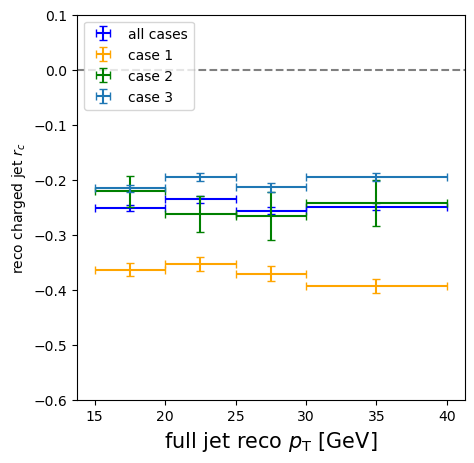

In [68]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], rc_allfake_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_allfake_bs_vs_pts_array, capsize=3, color='b', ls='none', label='all cases')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_fake1_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_fake1_bs_vs_pts_array, capsize=3, color='orange', ls='none', label='case 1')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_fake2_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_fake2_bs_vs_pts_array, capsize=3, color='g', ls='none', label='case 2')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_fake3_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_fake3_bs_vs_pts_array, capsize=3, ls='none', label='case 3')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')
plt.title('')

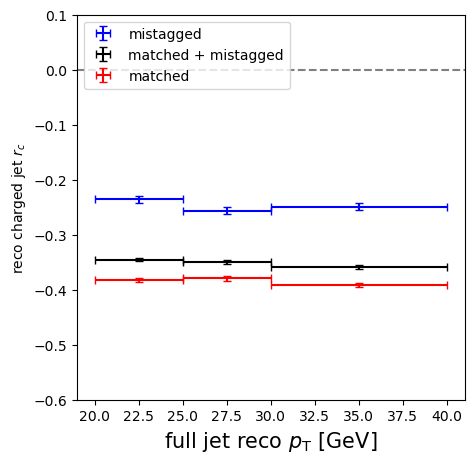

In [69]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_allfake_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_allfake_bs_vs_pts_array[1:], capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([22.5, 27.5, 35], rc_allreco_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_allreco_bs_vs_pts_array[1:], capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:], capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [70]:
np.array(rc_allreco_bs_vs_pts_array)-np.array(rc_match_bs_vs_pts_array)

array([0.04120929, 0.03725944, 0.02994666, 0.03321724])

1.2 Fake correction

In [71]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [72]:
df_match_15 = applyCut(df_match, '15 < pts < 20')
df_fake_15 = applyCut(df_allfake, '15 < pts < 20')

In [73]:
y_match_rec,yerr_match_rec,x = calc_hist(df_match_15[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_15['ws'], density=True)
y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_15[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_15['ws'], density=True)

In [74]:
print(y_fake_rec/sum(y_fake_rec))
print(yerr_fake_rec/sum(y_fake_rec))
print(y_match_rec/sum(y_match_rec))
print(yerr_match_rec/sum(y_match_rec))

[0.62543183 0.37456817]
[0.00651936 0.00440029]
[0.69372956 0.30627044]
[0.00469157 0.00285177]


In [20]:
df_match_20 = applyCut(df_match, '20 < pts < 25')
df_fake_20 = applyCut(df_allfake, '20 < pts < 25')

In [21]:
y_match_rec,yerr_match_rec,x = calc_hist(df_match_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_20['ws'], density=True)
y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_20['ws'], density=True)

In [22]:
print(y_fake_rec/sum(y_fake_rec))
print(yerr_fake_rec/sum(y_fake_rec))
print(y_match_rec/sum(y_match_rec))
print(yerr_match_rec/sum(y_match_rec))

[0.61873109 0.38126891]
[0.00736728 0.00586746]
[0.69209685 0.30790315]
[0.00525327 0.00329527]


In [75]:
df_match_25 = applyCut(df_match, '25 < pts < 30')
df_fake_25 = applyCut(df_allfake, '25 < pts < 30')

In [76]:
y_match_rec,yerr_match_rec,x = calc_hist(df_match_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_25['ws'], density=True)
y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_25['ws'], density=True)

In [77]:
print(y_fake_rec/sum(y_fake_rec))
print(yerr_fake_rec/sum(y_fake_rec))
print(y_match_rec/sum(y_match_rec))
print(yerr_match_rec/sum(y_match_rec))

[0.62803764 0.37196236]
[0.00973597 0.00815654]
[0.68951847 0.31048153]
[0.00568226 0.00444353]


In [26]:
df_match_30 = applyCut(df_match, '30 < pts < 40')
df_fake_30 = applyCut(df_allfake, '30 < pts < 40')

In [27]:
y_match_rec,yerr_match_rec,x = calc_hist(df_match_30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_30['ws'], density=True)
y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_30['ws'], density=True)

In [28]:
print(y_fake_rec/sum(y_fake_rec))
print(yerr_fake_rec/sum(y_fake_rec))
print(y_match_rec/sum(y_match_rec))
print(yerr_match_rec/sum(y_match_rec))

[0.62463995 0.37536005]
[0.0111834  0.00856057]
[0.6959566 0.3040434]
[0.00564118 0.00365521]


2. pT correction

In [78]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)] ]

In [79]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[1])

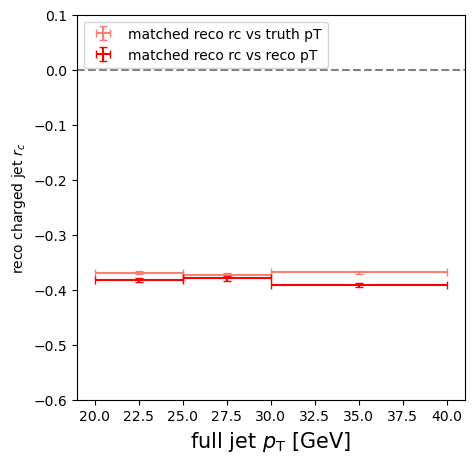

In [80]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:], capsize=3, color='salmon', ls='none', label='matched reco rc vs truth pT')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:], capsize=3, color='r', ls='none', label='matched reco rc vs reco pT')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [81]:
df_truthpt_15 = applyCut(df_match, '15 < pt < 20')
df_recopt_15 = applyCut(df_match, '15 < pts < 20')

In [82]:
y_truth,yerr_truth,x = calc_hist(df_truthpt_15[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_truthpt_15['ws'], density=True)
y_reco,yerr_reco,x = calc_hist(df_recopt_15[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_recopt_15['ws'], density=True)

In [83]:
print(y_truth/sum(y_truth))
print(yerr_truth/sum(y_truth))
print(y_reco/sum(y_reco))
print(yerr_reco/sum(y_reco))

[0.69412398 0.30587602]
[0.00487011 0.00292686]
[0.69372956 0.30627044]
[0.00469157 0.00285177]


In [84]:
df_truthpt_20 = applyCut(df_match, '20 < pt < 25')
df_recopt_20 = applyCut(df_match, '20 < pts < 25')

In [85]:
y_truth,yerr_truth,x = calc_hist(df_truthpt_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_truthpt_20['ws'], density=True)
y_reco,yerr_reco,x = calc_hist(df_recopt_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_recopt_20['ws'], density=True)

In [86]:
print(y_truth/sum(y_truth))
print(yerr_truth/sum(y_truth))
print(y_reco/sum(y_reco))
print(yerr_reco/sum(y_reco))

[0.68434607 0.31565393]
[0.00423681 0.00288002]
[0.69209685 0.30790315]
[0.00525327 0.00329527]


In [87]:
df_truthpt_25 = applyCut(df_match, '25 < pt < 30')
df_recopt_25 = applyCut(df_match, '25 < pts < 30')

In [88]:
y_truth,yerr_truth,x = calc_hist(df_truthpt_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_truthpt_25['ws'], density=True)
y_reco,yerr_reco,x = calc_hist(df_recopt_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_recopt_25['ws'], density=True)

In [89]:
print(y_truth/sum(y_truth))
print(yerr_truth/sum(y_truth))
print(y_reco/sum(y_reco))
print(yerr_reco/sum(y_reco))

[0.68667109 0.31332891]
[0.00443493 0.00327646]
[0.68951847 0.31048153]
[0.00568226 0.00444353]


In [90]:
df_truthpt_30 = applyCut(df_match, '30 < pt < 40')
df_recopt_30 = applyCut(df_match, '30 < pts < 40')

In [91]:
y_truth,yerr_truth,x = calc_hist(df_truthpt_30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_truthpt_30['ws'], density=True)
y_reco,yerr_reco,x = calc_hist(df_recopt_30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_recopt_30['ws'], density=True)

In [92]:
print(y_truth/sum(y_truth))
print(yerr_truth/sum(y_truth))
print(y_reco/sum(y_reco))
print(yerr_reco/sum(y_reco))

[0.68398949 0.31601051]
[0.00434381 0.00321012]
[0.6959566 0.3040434]
[0.00564118 0.00365521]


In [94]:
w1 = np.array([[0.96134037, 1.08756746], [0.95932244, 1.09143399],[0.961354  , 1.08582516],[0.94320187, 1.13001115]])

Reweight PYTHIA+GEANT to match data after fake subtraction

In [95]:
w_new = []
for i in range(0, df_match.shape[0]):
    if (df_match.iloc[i]['pts'] > 15 and df_match.iloc[i]['pts'] < 20):
        if (df_match.iloc[i]['bs']==-1):
            w_new.append(df_match.iloc[i]['ws']*w1[0][0])
        else:
            w_new.append(df_match.iloc[i]['ws']*w1[0][1])
    elif (df_match.iloc[i]['pts'] > 20 and df_match.iloc[i]['pts'] < 25):
        if (df_match.iloc[i]['bs']==-1):
            w_new.append(df_match.iloc[i]['ws']*w1[1][0])
        else:
            w_new.append(df_match.iloc[i]['ws']*w1[1][1])
    elif (df_match.iloc[i]['pts'] > 25 and df_match.iloc[i]['pts'] < 30):
        if (df_match.iloc[i]['bs']==-1):
            w_new.append(df_match.iloc[i]['ws']*w1[2][0])
        else:
            w_new.append(df_match.iloc[i]['ws']*w1[2][1])
    elif (df_match.iloc[i]['pts'] > 30 and df_match.iloc[i]['pts'] < 40):
        if (df_match.iloc[i]['bs']==-1):
            w_new.append(df_match.iloc[i]['ws']*w1[3][0])
        else:
            w_new.append(df_match.iloc[i]['ws']*w1[3][1])
    else:
        w_new.append(df_match.iloc[i]['ws'])
df_match['w_new'] = w_new # 

/tmp/ipykernel_1170818/1818643307.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_match['w_new'] = w_new #


In [96]:
def getRcAndErrNew(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w_new'])
        nss = sum(df[df.b==+1]['w_new'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['w_new'])
        nss = sum(df[df.bs==+1]['w_new'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n_array = []
    wtot_array = []
    for i in range(0, len(w_array)):
        n_array.append( df[df.w_new == w_array[i]].shape[0] )
        wtot_array.append( sum(df[df.w_new == w_array[i]]['w_new']) )
    n = 0
    for i in range(0, len(w_array)):
        if (wtot_array[i] != 0):
            n += wtot_array[i]*n_array[i]/sum(wtot_array)
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err

In [97]:
w_array = np.unique(df_match['w_new'])

In [98]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)] ]
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25) & (df_match.ws<1e-9)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)] ]

In [99]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[1])

rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[1])

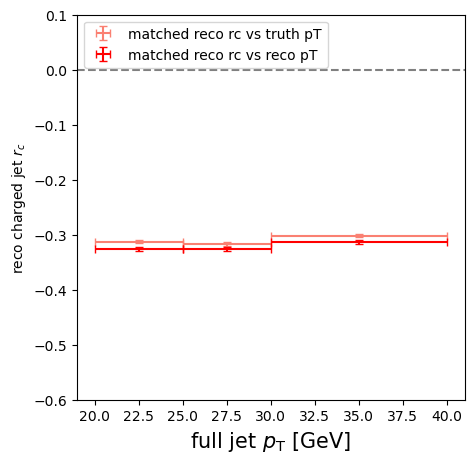

In [100]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:], capsize=3, color='salmon', ls='none', label='matched reco rc vs truth pT')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:], capsize=3, color='r', ls='none', label='matched reco rc vs reco pT')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

Results with doing both steps with new embedding

In [101]:
rc_match_bs_vs_pt_array

[-0.33444223323349337,
 -0.3128009657177392,
 -0.31669506178920137,
 -0.3014920972717453]

In [102]:
rc_err_match_bs_vs_pt_array

[0.0027871221516836756,
 0.0029702983770095565,
 0.003484168601946511,
 0.0029518071714300558]

Results with doing step 1 with old embedding and step 2 with new embedding

In [53]:
rc_match_bs_vs_pt_array

[-0.333731739070854,
 -0.3196067787322059,
 -0.3308912178265874,
 -0.3161598555225893]

In [54]:
rc_err_match_bs_vs_pt_array

[0.0027878684285193123,
 0.002963211038245022,
 0.0034662952224242187,
 0.0029371309750964715]

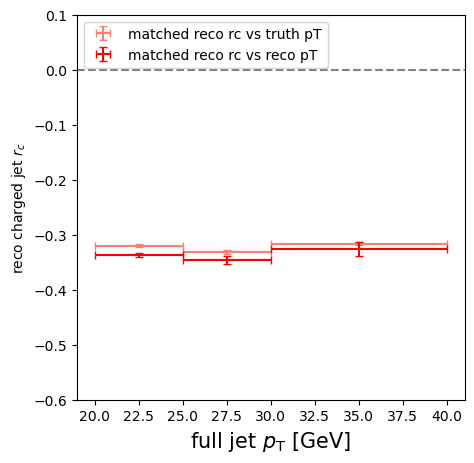

In [46]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:], capsize=3, color='salmon', ls='none', label='matched reco rc vs truth pT')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=[0.003328304308617994, 0.006772192457235017, 0.012550873791080731], capsize=3, color='r', ls='none', label='matched reco rc vs reco pT')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

3. rc corrections

In [53]:
rc_match_b_vs_pt_array = []
rc_err_match_b_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_b_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'b')[0])
    rc_err_match_b_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'b')[1])

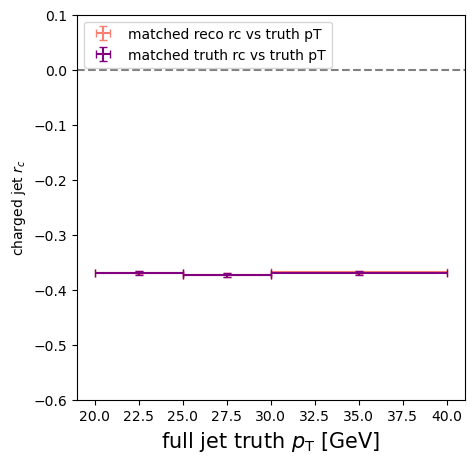

In [54]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:], capsize=3, color='salmon', ls='none', label='matched reco rc vs truth pT')
plt.errorbar([22.5, 27.5, 35], rc_match_b_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_b_vs_pt_array[1:], capsize=3, color='purple', ls='none', label='matched truth rc vs truth pT')
plt.xlabel('full jet truth $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [55]:
df_alltruth = pd.read_csv("/vast/palmer/home.grace/ys668/output/run12/all0818_2_alltruth.csv")

In [56]:
df_alltruth_pt_array = [ df_alltruth[(df_alltruth.pt>15) & (df_alltruth.pt<20)],\
                       df_alltruth[(df_alltruth.pt>20) & (df_alltruth.pt<25)],\
                       df_alltruth[(df_alltruth.pt>25) & (df_alltruth.pt<30)],\
                       df_alltruth[(df_alltruth.pt>30) & (df_alltruth.pt<40)] ]

In [57]:
rc_alltruth_b_vs_pt_array = []
rc_err_alltruth_b_vs_pt_array = []
for i in range(0, len(df_alltruth_pt_array)):
    rc_alltruth_b_vs_pt_array.append(getRcAndErr(df_alltruth_pt_array[i], 'b')[0])
    rc_err_alltruth_b_vs_pt_array.append(getRcAndErr(df_alltruth_pt_array[i], 'b')[1])

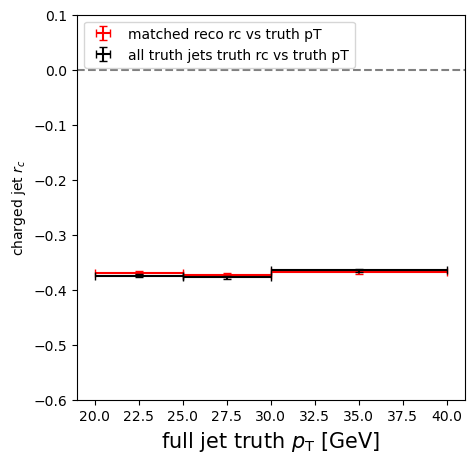

In [58]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:], capsize=3, color='r', ls='none', label='matched reco rc vs truth pT')
plt.errorbar([22.5, 27.5, 35], rc_alltruth_b_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_alltruth_b_vs_pt_array[1:], capsize=3, color='k', ls='none', label='all truth jets truth rc vs truth pT')
plt.xlabel('full jet truth $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

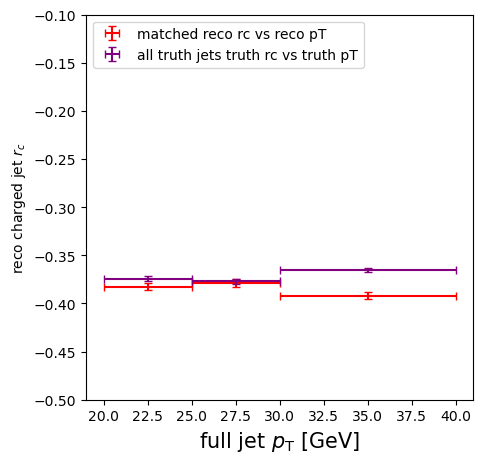

In [59]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:], capsize=3, color='r', ls='none', label='matched reco rc vs reco pT')
plt.errorbar([22.5, 27.5, 35], rc_alltruth_b_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_alltruth_b_vs_pt_array[1:], capsize=3, color='purple', ls='none', label='all truth jets truth rc vs truth pT')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.5,-0.1)
plt.legend(loc='upper left')